# 02 — Baseline reproduction
**Setup, historical smoke test, and full benchmark in one notebook.** Run the cells using the published small CSV and JSON files; GPU inference is not required.

**RQ1 (Chapter 6).** This notebook checks archived predictions, verifies the reference manifest and recomputes aggregate metrics. It does not rerun model inference.

## 1. Historical setup and smoke test
One normal Bottle reference, 83 test images, and archived prediction scores. The original smoke test used the earlier dataset revision; the full baseline uses the verified official dataset.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
import hashlib
from sklearn.metrics import roc_auc_score
folder = root / "results/bottle_smoke_test/bottle_1shot_seed0"
record = json.loads((folder / "metrics.json").read_text())
display(pd.Series({k: record[k] for k in ["model", "resolution", "shots", "seed", "reference_image", "rotation", "masking", "dataset_revision", "checkpoint_sha256"]}).to_frame("Run settings"))

,Run settings
model,dinov2_vits14
resolution,448
shots,1
seed,0
reference_image,000.png
rotation,True
masking,False
dataset_revision,c75b39616f84db43677bcc8228caaafaf5096d7f
checkpoint_sha256,b938bf1bc15cd2ec0feacfe3a1bb553fe8ea9ca46a7e1d...


## From reference to image score
The frozen model represents the reference as patch features. Rotation augmentation expands the reference bank. Each query patch is compared with the nearest normal feature. The highest-distance patches contribute to the image score. The CSV stores the resulting scores from inference; this cell checks their provenance and ranking.

In [2]:
predictions = folder / "predictions.csv"
assert hashlib.sha256(predictions.read_bytes()).hexdigest() == "45d8030895b1ba7c25a025c8fa5551749ea61f5f564903db40d2738325bdaccd"
scores = pd.read_csv(predictions)
assert scores.image.is_unique and len(scores) == record["test_images"]
assert scores.label.value_counts().to_dict() == {0: 20, 1: 63}
assert np.array_equal(scores.label, (~scores.image.str.startswith("good/")).astype(int))
auc = roc_auc_score(scores.label, scores.anomaly_score)
assert abs(auc - record["image_auroc"]) < 1e-12
display(scores.groupby("label").anomaly_score.agg(["count", "min", "median", "max"]).rename(index={0:"Normal", 1:"Defective"}))
print(f"Recomputed image AUROC: {auc:.12f}")

,count,min,median,max
label,,,,
Normal,20,0.135813,0.159494,0.244535
Defective,63,0.224727,0.385942,0.733876


Recomputed image AUROC: 0.998412698413


## Which pairs overlap?
At AUROC close to one, inspecting the actual pairs is more informative than rounding the score to 100%.

In [3]:
normal = scores.query("label == 0")
defective = scores.query("label == 1")
pairs = defective.merge(normal, how="cross", suffixes=("_defect", "_normal"))
overlap = pairs.query("anomaly_score_defect <= anomaly_score_normal")
display(overlap[["image_defect", "anomaly_score_defect", "image_normal", "anomaly_score_normal"]].reset_index(drop=True))

,image_defect,anomaly_score_defect,image_normal,anomaly_score_normal
0,broken_small/000.png,0.228442,good/001.png,0.244535
1,contamination/019.png,0.224727,good/001.png,0.244535


The smoke test validates image-level scoring for one reference in one category. It is not a paper reproduction. See [the original record](../research_logs/bottle_smoke_test.md).

## 2. Full baseline reproduction
All 45 archived evaluations: 15 categories, three fixed reference choices, one true normal reference per run. Equal-weight category means.

In [4]:
folder = root / "reports/baseline_reproduction"
runs = pd.read_csv(folder / "per_run.csv")
manifest = json.loads((root / "protocols/adino_mvtec_1shot_448_references.json").read_text())
expected = {(cat, int(seed)): ref for cat, refs in manifest["references"].items() for seed, ref in refs.items()}
assert len(runs) == len(expected) == 45 and not runs.duplicated(["category","seed"]).any()
assert set(zip(runs.category, runs.seed)) == set(expected)
for row in runs.itertuples():
    ref = expected[row.category, row.seed]
    assert (row.reference, row.reference_sha256) == (ref["path"], ref["sha256"])
print(f"{runs.category.nunique()} categories × {runs.seed.nunique()} references; {len(runs)} verified run rows")

15 categories × 3 references; 45 verified run rows


## Primary and secondary metrics
Image AUROC, AP, and F1-max assess image scores. Pixel AUROC, F1-max, and AUPRO assess localization. Pixel AUPRO integrates region overlap up to a false-positive rate of 0.30. F1-max uses the best threshold for the evaluated scores.

In [5]:
paper_percent = pd.Series({"image_auroc":96.5, "image_ap":98.1, "image_f1max":96.0,
                           "pixel_auroc":96.3, "pixel_f1max":57.9, "pixel_aupro":91.7})
metrics = paper_percent.index.tolist()
by_category = runs.groupby("category")[metrics].mean()
macro = by_category.mean()
archived = json.loads((folder / "summary.json").read_text())["metrics"]
np.testing.assert_allclose(macro, [archived[m]["macro_mean"] for m in metrics], atol=1e-12, rtol=0)
comparison = pd.DataFrame({"Thesis (%)":100 * macro, "Paper (%)":paper_percent,
                           "Difference (pp)":100 * macro - paper_percent})
display(comparison.round(3))

,Thesis (%),Paper (%),Difference (pp)
image_auroc,96.519,96.5,0.019
image_ap,98.145,98.1,0.045
image_f1max,95.957,96.0,-0.043
pixel_auroc,96.262,96.3,-0.038
pixel_f1max,57.939,57.9,0.039
pixel_aupro,91.720,91.7,0.020


Published comparison: Damm et al., *AnomalyDINO: Boosting Patch-based Few-shot Anomaly Detection with DINOv2*, WACV 2025, Table 2, one shot, AnomalyDINO-S (448). The published means are rounded to one decimal percentage point; differences at that scale cannot establish improvement.

## Variation across categories
Sort by region overlap to see where localization is hardest. The three references share test images, so variation across references measures reference sensitivity.

,image_auroc,image_ap,image_f1max,pixel_auroc,pixel_f1max,pixel_aupro
category,,,,,,
transistor,90.89,87.00,83.18,84.00,39.57,64.36
zipper,98.85,99.71,98.47,92.26,44.78,83.19
cable,91.56,95.61,88.68,93.45,62.81,88.19
tile,99.98,99.99,99.80,95.80,65.12,88.65
screw,89.15,95.98,90.31,97.88,38.33,90.78
metal_nut,99.89,99.97,99.82,95.96,73.32,93.77
wood,98.83,99.65,97.80,94.71,65.31,93.86
toothbrush,99.63,99.86,98.87,99.14,65.25,94.34
grid,99.19,99.75,99.12,99.12,46.03,96.09


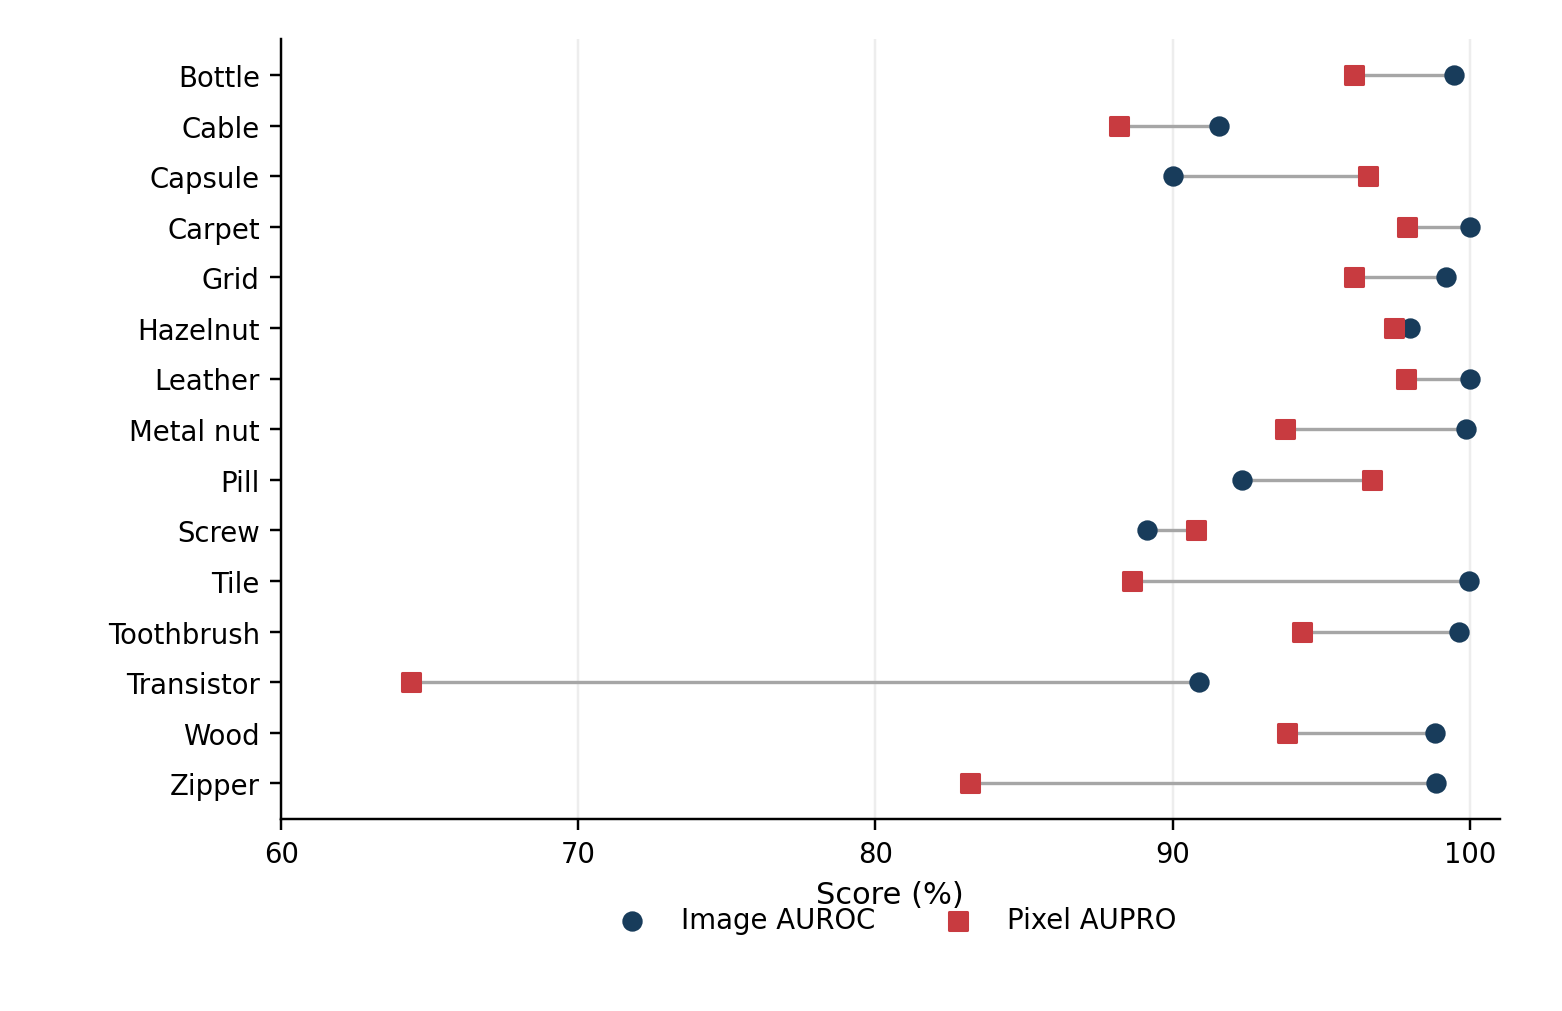

In [6]:
display((100 * by_category.sort_values("pixel_aupro")).round(2))
import sys
from tempfile import mkdtemp
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from scripts.visualize import generate_publication_assets
output = root / "outputs/notebook_figures"
output.mkdir(parents=True, exist_ok=True)
generated = generate_publication_assets(Path(mkdtemp(prefix="baseline_", dir=output)) / "publication_assets", study="baseline")
FIG = generated["figures"]
from IPython.display import Image
display(Image(filename=str(FIG / "07_baseline_category_comparison.png")))


The six reproduced macro means agree with the published means at the displayed precision. These clean-condition results supply the paired baselines for [Robustness Analysis](03_robustness_analysis.ipynb).